# DeepPCB 모델 추론 시연

검증 세트에서 최대 5개의 이미지 쌍을 확인하고 fast 및 accurate 모델의 결함 예측을 정답과 비교합니다. 추론 시간은 별도로 검증 이미지 50쌍에서 측정합니다. 이 노트북은 학습을 수행하지 않으며 `runs/`에 저장된 체크포인트와 보정 임계값을 사용합니다.

> 정확도·정밀도·재현율은 선택한 검증 이미지들에 대한 객체 탐지 지표입니다. 정확도는 프로젝트 정의인 `TP / (TP + FP + FN)`을 사용합니다. 전체 테스트 결과와는 다릅니다.


## 이 노트북의 실행 순서

1. **환경 확인:** 프로젝트 루트, 데이터, 검증 분할, 체크포인트, 보정 파일을 찾고 체크포인트 해시를 확인합니다.
2. **검증 예시:** val 분할에서 최대 5개 이미지 쌍의 템플릿·검사 이미지와 정답 상자를 확인합니다.
3. **모델 비교:** fast와 accurate 모델의 예측을 같은 5개 이미지에서 시각화하고, fast 모델이 IoU 0.33 기준으로 놓친 정답 상자를 출력합니다.
4. **속도 측정:** 최대 50개 val 이미지에서 모델 로딩과 파일 읽기를 제외한 추론 시간을 측정합니다.
5. **지표와 결과:** 선택한 이미지들의 지표를 보여주고, `runs/test_metrics.json`이 있으면 전체 테스트 평가도 표시합니다.

**실행 전 준비:** Python 3.10 이상과 프로젝트 `requirements.txt` 패키지가 필요합니다. 가상환경이 다른 컴퓨터의 Python 경로를 참조하면 해당 환경을 다시 만들어야 합니다. PyCharm에서 해당 프로젝트 환경을 노트북 커널로 선택하세요. 프로젝트의 `README.md`에 있는 01~05 스크립트 실행을 마쳐야 합니다. 전체 테스트 지표를 보려면 06도 실행하세요. 데이터가 5쌍 또는 50쌍보다 적으면 사용 가능한 수만 처리합니다. 이 노트북은 모델을 다시 학습하지 않습니다.


## 모델은 이렇게 동작합니다

이 프로젝트는 같은 PCB의 **정상 템플릿 이미지**와 **검사 이미지**를 함께 입력받아 결함의 위치와 종류를 찾습니다. 두 이미지는 서로 정렬되어 있다고 가정합니다. 찾는 결함은 `open`, `short`, `mousebite`, `spur`, `spurious copper`, `pin hole`의 여섯 종류입니다.

### 빠른 모델 (`fast`)

1. 템플릿 이미지와 검사 이미지를 각각 흑백으로 변환하고, 밝기 기준으로 이진화해 픽셀 차이를 찾습니다. 구리 패턴이 어둡거나 밝은 경우를 설정에 따라 구분합니다.
2. 서로 붙어 있는 변화 픽셀을 하나의 영역으로 묶어 결함 후보 상자를 만듭니다. 너무 작은 영역은 제외합니다.
3. 후보 영역 주변을 잘라 `[검사 이미지, 템플릿, 추가 영역 마스크, 누락 영역 마스크]`의 네 채널 패치로 구성합니다.
4. CNN이 각 패치를 배경 또는 여섯 결함 종류 중 하나로 분류합니다. 분류 결과는 후보 상자에 연결됩니다.
5. 점수 임계값으로 낮은 신뢰도의 예측을 제거하고, NMS로 서로 많이 겹치는 중복 상자를 정리합니다.

이 방식은 후보 영역만 분류하므로 빠릅니다. 다만 결함이 처음 후보 생성 단계에서 누락되면 뒤의 분류기가 찾아낼 수 없습니다.

### 정확도 모델 (`accurate`)

1. 같은 ResNet18 가중치를 공유하는 두 인코더가 검사 이미지와 템플릿의 특징을 각각 추출합니다.
2. 여러 해상도에서 두 이미지의 특징과 특징 차이를 결합합니다. 특징 차이는 템플릿과 검사 이미지가 서로 다른 부분을 강조합니다.
3. FPN(Feature Pyramid Network)이 다양한 크기의 특징 지도를 만들고, Faster R-CNN의 RPN이 결함 후보 상자를 제안합니다.
4. RoI 분류기가 후보별 결함 종류와 점수를 예측하고, 상자 회귀기가 결함 위치를 더 정확하게 조정합니다.
5. 점수 임계값과 NMS를 적용해 낮은 점수와 중복 예측을 정리합니다.

이 방식은 전체 이미지의 특징을 살펴 후보를 찾기 때문에 빠른 모델보다 계산량이 많을 수 있습니다.

### 학습부터 추론까지

1. `01_prepare_data.py`가 데이터와 정답 라벨을 확인하고 학습·검증 분할을 만듭니다.
2. `02_check_candidates.py`가 빠른 모델의 후보 생성 단계에서 정답 결함을 충분히 포함하는지 확인합니다.
3. `03_train_fast.py`와 `04_train_accurate.py`가 각각 모델을 학습하고 체크포인트를 저장합니다.
4. `05_calibrate_on_val.py`가 검증 데이터에서 모델별 점수 임계값을 정합니다.
5. 이 노트북은 저장된 체크포인트와 임계값을 불러와 예측 결과와 실행 시간을 보여 줍니다. 노트북 안에서 모델을 다시 학습하지는 않습니다.
6. 전체 테스트 세트 평가는 `06_evaluate_on_test.py`에서 별도로 수행합니다.

예측 상자와 정답 상자는 **같은 결함 종류이며 IoU가 0.33 이상일 때** 일치한 것으로 계산합니다. 일부 검증 이미지에서 계산한 지표는 전체 데이터의 성능을 대표하지 않으므로 참고용으로 해석해야 합니다.

## 1. 환경과 파일 확인

노트북을 프로젝트 폴더 어디에서 열어도 `src/`, `configs/`, `runs/`를 자동으로 찾습니다. 두 체크포인트와 `calibration.json`이 필요합니다. 파일이 없거나 보정 결과가 오래된 경우, 오류 메시지의 안내에 따라 앞선 스크립트를 다시 실행하세요.

In [9]:
from pathlib import Path
import sys

search_roots = [Path.cwd(), *Path.cwd().parents]
candidate_roots = search_roots + [p / 'deeppcb' for p in search_roots] + [p / 'data_example' / 'DeepPCB' / 'deeppcb' for p in search_roots]
PROJECT_ROOT = next((p for p in candidate_roots if (p / 'src' / 'evaluation.py').is_file()), None)
if PROJECT_ROOT is None:
    raise FileNotFoundError('deeppcb 프로젝트 폴더를 찾지 못했습니다. notebooks 폴더 또는 deeppcb 폴더에서 노트북을 여세요.')
sys.path.insert(0, str(PROJECT_ROOT / 'src'))
print('프로젝트:', PROJECT_ROOT)
print('데이터:', (PROJECT_ROOT / 'data').is_dir())
print('분할 CSV:', (PROJECT_ROOT / 'runs' / 'splits.csv').is_file())
print('체크포인트:', {name: (PROJECT_ROOT / 'runs' / f'{name}.pt').is_file() for name in ('fast', 'accurate')})

프로젝트: C:\Users\Win11Pro\Documents\18_kdt_팀프로젝트_5차~1123\data_example\DeepPCB\deeppcb
데이터: True
분할 CSV: True
체크포인트: {'fast': True, 'accurate': True}


In [10]:
import importlib.util
import sys
from IPython.display import display, Markdown

if sys.version_info < (3, 10):
    raise RuntimeError(f"Python 3.10 이상이 필요합니다. 현재 커널: {sys.version.split()[0]} ({sys.executable})")
required_modules = ('numpy', 'matplotlib', 'torch', 'torchvision', 'PIL', 'yaml', 'scipy')
missing_modules = [name for name in required_modules if importlib.util.find_spec(name) is None]
if missing_modules:
    raise RuntimeError(
        f"현재 노트북 커널({sys.executable})에 필수 패키지가 없습니다: {', '.join(missing_modules)}.\n"
        f"프로젝트 가상환경의 Python 경로가 유효한지 확인하고, Python 3.10 이상 환경에서 `{PROJECT_ROOT / 'requirements.txt'}`를 설치한 뒤 해당 환경을 노트북 커널로 선택하세요.\n"
        "PyTorch/torchvision은 README.md 안내에 따라 장치에 맞는 호환 빌드로 설치해야 합니다."
    )

import json
import time
import numpy as np
import matplotlib.pyplot as plt
import torch
from PIL import Image, ImageDraw

from dataset import CLASS_NAMES, load_pair, read_split_csv
from evaluation import MATCH_IOU, file_sha256, operating_metrics, predict_one
from candidates import box_iou
from training import load_checkpoint, load_config, select_device

configs = {
    'fast': load_config(PROJECT_ROOT / 'configs' / 'fast.yaml'),
    'accurate': load_config(PROJECT_ROOT / 'configs' / 'accurate.yaml'),
}
runs_dir = PROJECT_ROOT / 'runs'
required = [runs_dir / 'splits.csv', runs_dir / 'calibration.json', runs_dir / 'fast.pt', runs_dir / 'accurate.pt']
missing = [str(path) for path in required if not path.is_file()]
if missing:
    raise FileNotFoundError('필요한 결과 파일이 없습니다: ' + ', '.join(missing) + '\n먼저 01~05 스크립트를 실행해 데이터 분할, 체크포인트, 보정 결과를 만드세요.')
calibration = json.loads((runs_dir / 'calibration.json').read_text(encoding='utf-8'))
for kind in ('fast', 'accurate'):
    checkpoint_path = runs_dir / f'{kind}.pt'
    expected = calibration['models'][kind]['checkpoint_sha256']
    if file_sha256(checkpoint_path) != expected:
        raise ValueError(f'{kind} 체크포인트가 calibration.json 생성 후 변경되었습니다. 05_calibrate_on_val.py를 다시 실행하세요.')
records = read_split_csv(runs_dir / 'splits.csv', 'val')
if not records:
    raise ValueError('검증 세트가 비어 있습니다. 먼저 01_prepare_data.py를 실행하세요.')
device = select_device('auto')
print(f'검증 이미지 {len(records)}장 | 장치: {device}' + (f' ({torch.cuda.get_device_name(0)})' if device.type == 'cuda' else ''))


검증 이미지 200장 | 장치: cuda (NVIDIA GeForce RTX 5060 Laptop GPU)


## 2. 검증 이미지 쌍 5개 확인

검증 세트 앞에서부터 최대 5개 샘플을 표시합니다. 템플릿과 검사 이미지를 행으로 나누어 보여주며, 검사 이미지의 빨간 상자는 정답 결함입니다.


C:\Users\Win11Pro\AppData\Local\Temp\ipykernel_3556\580548618.py:18: UserWarning: Glyph 53596 (\N{HANGUL SYLLABLE TEM}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
C:\Users\Win11Pro\AppData\Local\Temp\ipykernel_3556\580548618.py:18: UserWarning: Glyph 54540 (\N{HANGUL SYLLABLE PEUL}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
C:\Users\Win11Pro\AppData\Local\Temp\ipykernel_3556\580548618.py:18: UserWarning: Glyph 47551 (\N{HANGUL SYLLABLE RIS}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
C:\Users\Win11Pro\AppData\Local\Temp\ipykernel_3556\580548618.py:18: UserWarning: Glyph 44160 (\N{HANGUL SYLLABLE GEOM}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
C:\Users\Win11Pro\AppData\Local\Temp\ipykernel_3556\580548618.py:18: UserWarning: Glyph 49324 (\N{HANGUL SYLLABLE SA}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
C:\Users\Win11Pro\AppData\Local\Temp\ipykernel_3556\580548618.py:18: UserWarning: Glyph 51060 (\N{HANGUL SYLLABLE I}) missin

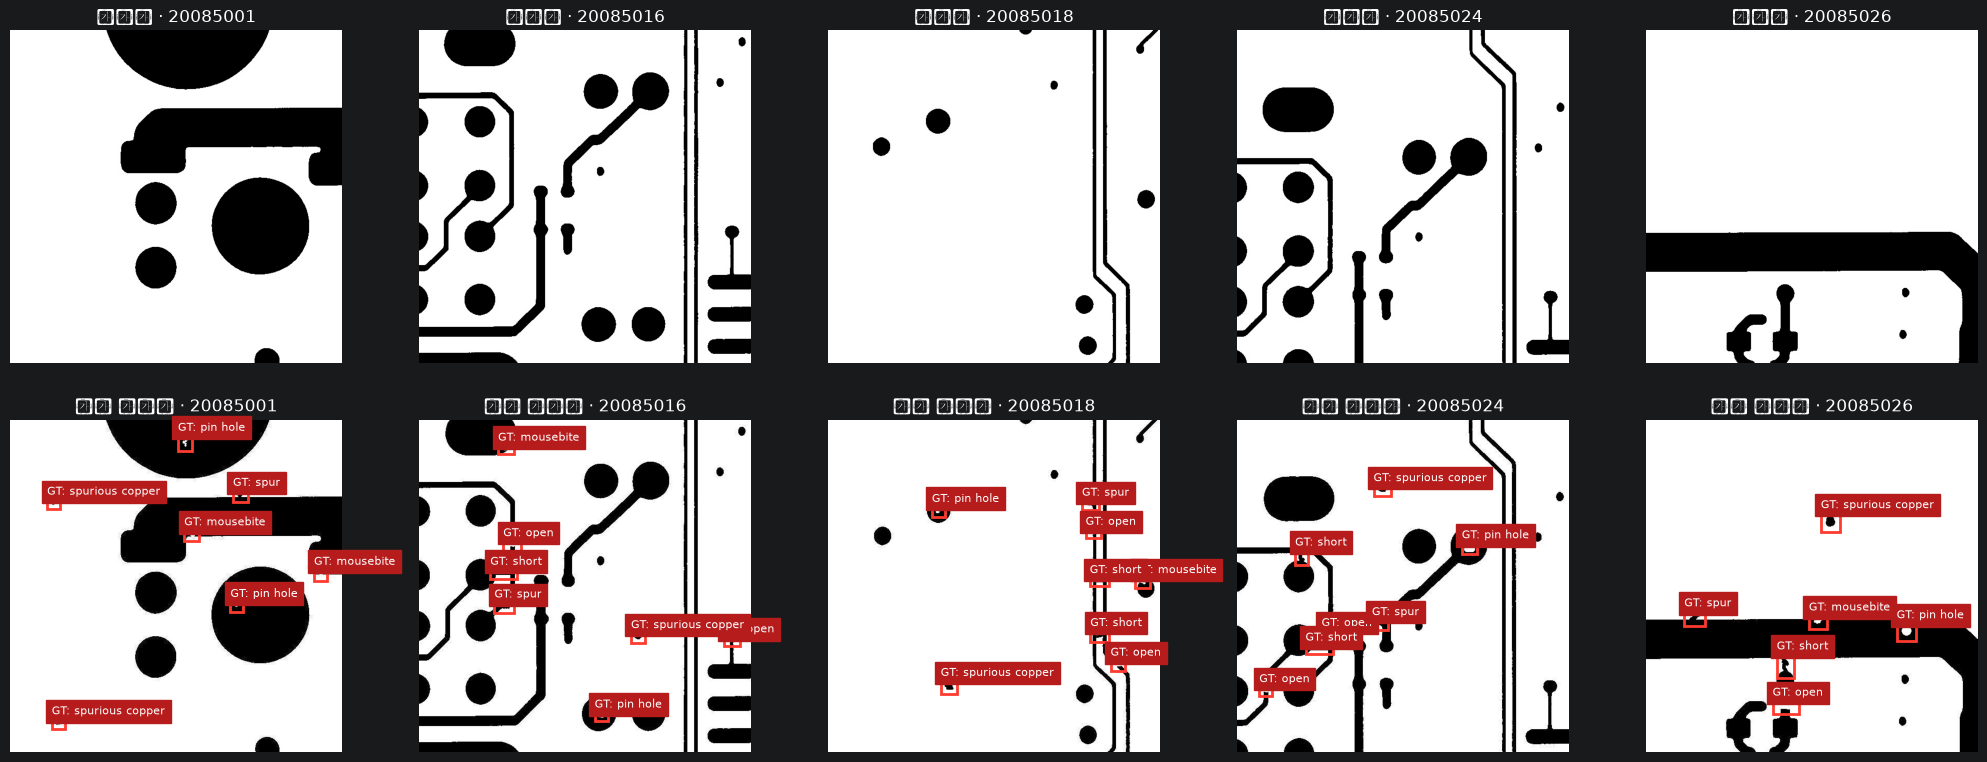

In [11]:
SAMPLE_COUNT = min(5, len(records))
sample_records = records[:SAMPLE_COUNT]
sample_data = []
fig, axes = plt.subplots(2, SAMPLE_COUNT, figsize=(4 * SAMPLE_COUNT, 8), squeeze=False)
for index, record in enumerate(sample_records):
    temp_image, test_image, gt_boxes, gt_classes = load_pair(Path(configs['fast']['data_root']), record)
    sample_data.append((record, temp_image, test_image, gt_boxes, gt_classes))
    axes[0, index].imshow(temp_image, cmap='gray', vmin=0, vmax=255)
    axes[0, index].set_title(f"템플릿 · {record['sample_id']}")
    axes[1, index].imshow(test_image, cmap='gray', vmin=0, vmax=255)
    axes[1, index].set_title(f"검사 이미지 · {record['sample_id']}")
    for box, cls in zip(gt_boxes, gt_classes):
        x1, y1, x2, y2 = map(int, box)
        axes[1, index].add_patch(plt.Rectangle((x1, y1), x2-x1, y2-y1, fill=False, edgecolor='#ff3b30', linewidth=2))
        axes[1, index].text(x1, max(0, y1-5), f'GT: {CLASS_NAMES[int(cls)]}', color='white', fontsize=8, backgroundcolor='#b71c1c')
for ax in axes.flat:
    ax.axis('off')
plt.tight_layout()


## 3. 두 모델로 5개 이미지 추론

각 모델은 체크포인트와 같은 검증 보정 임계값을 사용합니다. 각 행에서 템플릿, fast 예측, accurate 예측을 비교합니다. 예측 상자는 클래스별 색으로, 정답 상자는 빨간 점선으로 표시합니다.


In [12]:
models, predictions, thresholds, metrics = {}, {}, {}, {}
saved_configs = {}
truths = {}
for record, temp_image, test_image, gt_boxes, gt_classes in sample_data:
    truths[record['sample_id']] = (gt_boxes, gt_classes)
for kind, cfg in configs.items():
    model, saved_cfg = load_checkpoint(runs_dir / f'{kind}.pt', kind, device)
    saved_configs[kind] = saved_cfg
    threshold = float(calibration['models'][kind]['threshold'])
    thresholds[kind] = threshold
    models[kind] = model
    predictions[kind] = {}
    for record, temp_image, test_image, gt_boxes, gt_classes in sample_data:
        raw = predict_one(kind, model, saved_cfg, temp_image, test_image, record['sample_id'], device)
        predictions[kind][record['sample_id']] = [p for p in raw if p['score'] >= threshold]
    metrics[kind] = operating_metrics(
        [p for sample_predictions in predictions[kind].values() for p in sample_predictions],
        truths, threshold=threshold
    )
    count = sum(len(sample_predictions) for sample_predictions in predictions[kind].values())
    print(f'{kind}: 임계값={threshold:.2f}, 이미지={len(sample_data)}쌍, 예측={count}개')

print(f'\nfast 정답 누락 확인 (같은 클래스, IoU ≥ {MATCH_IOU:.2f} 기준):')
for record, _, _, gt_boxes, gt_classes in sample_data:
    sample_id = record['sample_id']
    sample_predictions = sorted(predictions['fast'][sample_id], key=lambda p: p['score'], reverse=True)
    matched = set()
    for pred in sample_predictions:
        candidates = [(index, box_iou(tuple(pred[k] for k in ('x1','y1','x2','y2')), tuple(box)))
                      for index, (box, cls) in enumerate(zip(gt_boxes, gt_classes))
                      if index not in matched and int(cls) == pred['class_id']]
        if candidates:
            best_index, best_iou = max(candidates, key=lambda item: item[1])
            if best_iou >= MATCH_IOU:
                matched.add(best_index)
    missed = [f"{CLASS_NAMES[int(gt_classes[index])]} #{index + 1}"
              for index in range(len(gt_classes)) if index not in matched]
    if missed:
        print(f"[놓침] {sample_id}: 빨간 정답 상자 {', '.join(missed)}")
    else:
        print(f"[검출] {sample_id}: 빨간 정답 상자 {len(gt_classes)}개 모두 검출")


fast: 임계값=0.53, 이미지=5쌍, 예측=31개
accurate: 임계값=0.95, 이미지=5쌍, 예측=36개

fast 정답 누락 확인 (같은 클래스, IoU ≥ 0.33 기준):
[놓침] 20085001: 빨간 정답 상자 spur #2
[놓침] 20085016: 빨간 정답 상자 open #1, short #3, spur #5
[검출] 20085018: 빨간 정답 상자 8개 모두 검출
[놓침] 20085024: 빨간 정답 상자 open #1, open #2, short #3, spur #5
[놓침] 20085026: 빨간 정답 상자 short #2, mousebite #3, spur #4


C:\Users\Win11Pro\AppData\Local\Temp\ipykernel_3556\1594015383.py:22: UserWarning: Glyph 53596 (\N{HANGUL SYLLABLE TEM}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
C:\Users\Win11Pro\AppData\Local\Temp\ipykernel_3556\1594015383.py:22: UserWarning: Glyph 54540 (\N{HANGUL SYLLABLE PEUL}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
C:\Users\Win11Pro\AppData\Local\Temp\ipykernel_3556\1594015383.py:22: UserWarning: Glyph 47551 (\N{HANGUL SYLLABLE RIS}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
C:\Users\Win11Pro\AppData\Local\Temp\ipykernel_3556\1594015383.py:22: UserWarning: Glyph 50696 (\N{HANGUL SYLLABLE YE}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
C:\Users\Win11Pro\AppData\Local\Temp\ipykernel_3556\1594015383.py:22: UserWarning: Glyph 52769 (\N{HANGUL SYLLABLE CEUG}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
C:\Users\Win11Pro\AppData\Local\Temp\ipykernel_3556\1594015383.py:22: UserWarning: Glyph 48744 (\N{HANGUL SYLLABLE BBAL

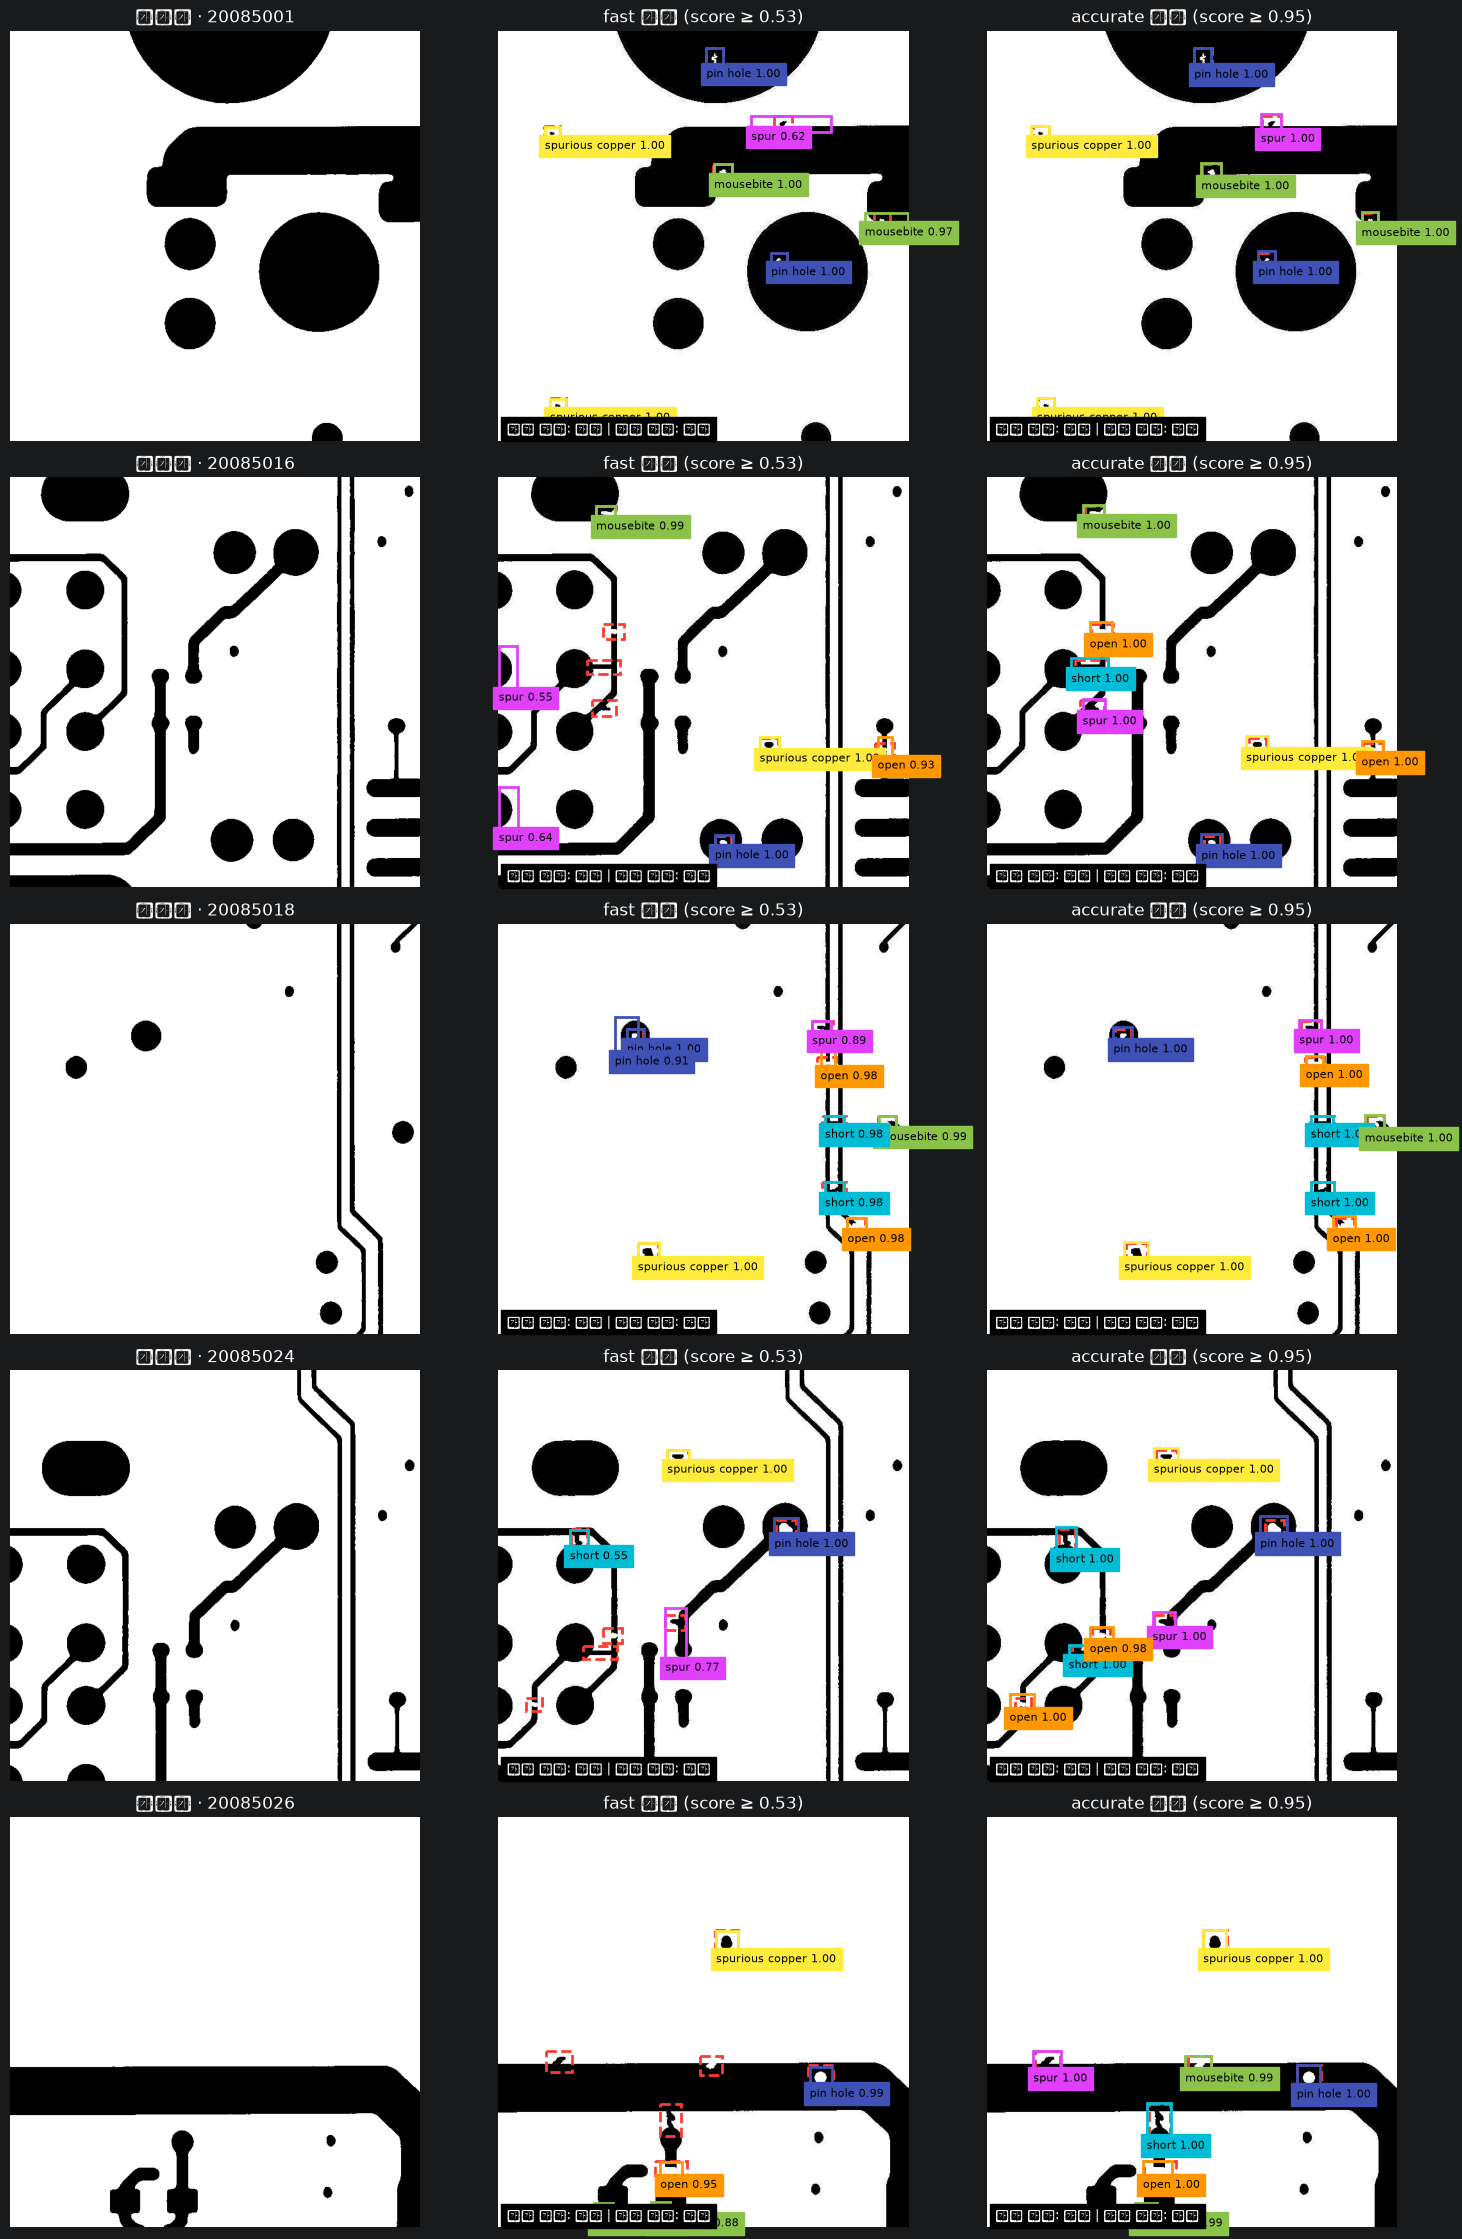

In [13]:
class_colors = {1:'#ff9800', 2:'#00bcd4', 3:'#8bc34a', 4:'#e040fb', 5:'#ffeb3b', 6:'#3f51b5'}
fig, axes = plt.subplots(SAMPLE_COUNT, 3, figsize=(15, 4.5 * SAMPLE_COUNT), squeeze=False)
for row, (record, temp_image, test_image, gt_boxes, gt_classes) in enumerate(sample_data):
    sample_id = record['sample_id']
    axes[row, 0].imshow(temp_image, cmap='gray', vmin=0, vmax=255)
    axes[row, 0].set_title(f'템플릿 · {sample_id}')
    for column, kind in ((1, 'fast'), (2, 'accurate')):
        ax = axes[row, column]
        ax.imshow(test_image, cmap='gray', vmin=0, vmax=255)
        ax.set_title(f"{kind} 예측 (score ≥ {thresholds[kind]:.2f})")
        for box, cls in zip(gt_boxes, gt_classes):
            x1, y1, x2, y2 = map(int, box)
            ax.add_patch(plt.Rectangle((x1,y1), x2-x1, y2-y1, fill=False, edgecolor='#ff3b30', linewidth=2, linestyle='--'))
        for pred in predictions[kind][sample_id]:
            x1, y1, x2, y2 = (int(pred[k]) for k in ('x1','y1','x2','y2'))
            color = class_colors[pred['class_id']]
            ax.add_patch(plt.Rectangle((x1,y1), x2-x1, y2-y1, fill=False, edgecolor=color, linewidth=2))
            ax.text(x1, min(test_image.shape[0]-2, y2+12), f"{CLASS_NAMES[pred['class_id']]} {pred['score']:.2f}", color='black', fontsize=8, backgroundcolor=color)
        ax.text(0.02, 0.02, '빨간 점선: 정답 | 색상 상자: 예측', transform=ax.transAxes, color='white', fontsize=9, backgroundcolor='black')
for ax in axes.flat:
    ax.axis('off')
plt.tight_layout()


## 4. 50개 이미지 쌍 추론 시간 측정

검증 세트에서 최대 50쌍을 사용합니다. 모델 로딩과 이미지 읽기 시간은 제외하고 `predict_one` 호출만 측정합니다. 첫 호출을 워밍업으로 제외하며, GPU 사용 시 CUDA 동기화로 측정 구간을 맞춥니다.


In [14]:
TIMING_COUNT = min(50, len(records))
timing_records = records[:TIMING_COUNT]
timing_data = []
for record in timing_records:
    temp_image, test_image, _, _ = load_pair(Path(configs['fast']['data_root']), record)
    timing_data.append((record, temp_image, test_image))
timing_results = {}
for kind in ('fast', 'accurate'):
    model = models[kind]
    cfg = saved_configs[kind]
    threshold = thresholds[kind]
    durations = []
    total_predictions = 0
    # Warm up once, then time every selected pair under the same conditions.
    first_record, first_temp, first_test = timing_data[0]
    predict_one(kind, model, cfg, first_temp, first_test, first_record['sample_id'], device)
    if device.type == 'cuda':
        torch.cuda.synchronize(device)
    for record, temp_image, test_image in timing_data:
        if device.type == 'cuda':
            torch.cuda.synchronize(device)
        start = time.perf_counter()
        raw = predict_one(kind, model, cfg, temp_image, test_image, record['sample_id'], device)
        if device.type == 'cuda':
            torch.cuda.synchronize(device)
        durations.append(time.perf_counter() - start)
        total_predictions += sum(p['score'] >= threshold for p in raw)
    measured = durations
    timing_results[kind] = {'images': len(timing_data), 'predictions': total_predictions,
        'mean_ms': float(np.mean(measured) * 1000), 'median_ms': float(np.median(measured) * 1000),
        'total_seconds': float(sum(durations))}
headers = ['모델', '이미지 쌍', '예측 수', '평균 추론(ms/쌍)', '중앙값(ms/쌍)', '총 시간(초)']
rows = []
for kind in ('fast', 'accurate'):
    result = timing_results[kind]
    rows.append([kind, result['images'], result['predictions'], f"{result['mean_ms']:.1f}", f"{result['median_ms']:.1f}", f"{result['total_seconds']:.2f}"])
table = '| ' + ' | '.join(headers) + ' |\n| ' + ' | '.join(['---'] * len(headers)) + ' |\n'
table += ''.join('| ' + ' | '.join(map(str, row)) + ' |\n' for row in rows)
display(Markdown(table))


| 모델 | 이미지 쌍 | 예측 수 | 평균 추론(ms/쌍) | 중앙값(ms/쌍) | 총 시간(초) |
| --- | --- | --- | --- | --- | --- |
| fast | 50 | 343 | 33.2 | 29.4 | 1.66 |
| accurate | 50 | 376 | 40.6 | 40.0 | 2.03 |


## 5. 5개 이미지 쌍 지표 비교

표는 위에서 선택한 검증 이미지 최대 5쌍을 합산해 평가합니다. 정확도는 객체 탐지용 `TP / (TP + FP + FN)` 정의이며, 전체 테스트 세트 지표는 아래 결과 파일에서 별도로 확인합니다.


In [15]:
from IPython.display import display, Markdown
headers = ['모델', '이미지 쌍', '정답 수', '예측 수', '정확도', '정밀도', '재현율']
rows = []
for kind in ('fast', 'accurate'):
    m = metrics[kind]
    rows.append([kind, m['images'], m['tp'] + m['fn'], sum(len(v) for v in predictions[kind].values()),
                 f"{m['accuracy']:.3f}", f"{m['precision']:.3f}", f"{m['recall']:.3f}"])
table = '| ' + ' | '.join(headers) + ' |\n| ' + ' | '.join(['---'] * len(headers)) + ' |\n'
table += ''.join('| ' + ' | '.join(map(str, row)) + ' |\n' for row in rows)
display(Markdown(table))


| 모델 | 이미지 쌍 | 정답 수 | 예측 수 | 정확도 | 정밀도 | 재현율 |
| --- | --- | --- | --- | --- | --- | --- |
| fast | 5 | 35 | 31 | 0.571 | 0.774 | 0.686 |
| accurate | 5 | 35 | 36 | 0.972 | 0.972 | 1.000 |


## 6. 전체 테스트 평가 결과

`06_evaluate_on_test.py`가 생성한 결과를 표시합니다. 해당 파일이 없으면 먼저 전체 평가 스크립트를 실행하세요. 테스트 결과를 이 노트북의 샘플 지표와 혼동하지 마세요.


In [16]:
test_report_path = runs_dir / 'test_metrics.json'
if test_report_path.is_file():
    test_report = json.loads(test_report_path.read_text(encoding='utf-8'))
    summary = []
    for kind, result in test_report['models'].items():
        op = result['operating']
        accuracy_text = f"{op['accuracy']:.3f}" if op.get('accuracy') is not None else '—'
        summary.append([kind, op['images'], accuracy_text,
                        f"{op['precision']:.3f}", f"{op['recall']:.3f}",
                        f"{result['loss']:.4f}" if result.get('loss') is not None else '—',
                        f"{op['f1']:.3f}", f"{result['ranking']['mAP_0_33']:.3f}"])
    headers = ['모델', '이미지 수', '정확도', '정밀도', '재현율', '손실', 'F1', 'mAP@0.33']
    table = '| ' + ' | '.join(headers) + ' |\n| ' + ' | '.join(['---'] * len(headers)) + ' |\n'
    table += ''.join('| ' + ' | '.join(map(str, row)) + ' |\n' for row in summary)
    display(Markdown(table))
else:
    print('전체 테스트 평가 결과가 없습니다. python src/06_evaluate_on_test.py 실행 후 이 셀을 다시 실행하세요.')

| 모델 | 이미지 수 | 정확도 | 정밀도 | 재현율 | 손실 | F1 | mAP@0.33 |
| --- | --- | --- | --- | --- | --- | --- | --- |
| fast | 500 | 0.656 | 0.855 | 0.738 | 0.1114 | 0.792 | 0.742 |
| accurate | 500 | 0.920 | 0.975 | 0.942 | 0.2640 | 0.958 | 0.987 |


## 다음 실행

새 체크포인트를 학습했다면 `05_calibrate_on_val.py`를 다시 실행해 보정 파일을 갱신한 뒤 노트북을 위에서부터 재실행하세요. 입력 경로와 분할 설정은 `configs/fast.yaml`, `configs/accurate.yaml`에서 관리합니다.